<a href="https://colab.research.google.com/github/ManaalShaikh/2D-Array-Matrix/blob/main/Deep_Learning_project_on_Iris_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Step 1:Import Libraries

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [3]:
#Step 2: Load the dataset

In [5]:
iris=load_iris()

X=iris.data
y=iris.target

print("Input Shape:",X.shape)
print("Output Shape:",y.shape)

print("Feature Names:",iris.feature_names)
print("Class Names:",iris.target_names)

Input Shape: (150, 4)
Output Shape: (150,)
Feature Names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Class Names: ['setosa' 'versicolor' 'virginica']


In [6]:
#Step 3:Split the dataset

In [7]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("Training Samples:",len(X_train))
print("Testing Samples:",len(X_test))

Training Samples: 120
Testing Samples: 30


In [ ]:
#Step 4:Feature Scaling

In [10]:
scaler=StandardScaler()

X_train=scaler.fit_transform(X_train)

X_test=scaler.transform(X_test)


In [11]:
#Step 5 :Convert Data into Pytorch Tensors

In [13]:
X_train=torch.tensor(X_train,dtype=torch.float32)
X_test=torch.tensor(X_test,dtype=torch.float32)
y_train=torch.tensor(y_train,dtype=torch.long)
y_test=torch.tensor(y_test,dtype=torch.long)

print(X_train.shape)
print(y_train.shape)

torch.Size([120, 4])
torch.Size([120])


/tmp/ipykernel_4082/1091613496.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_train=torch.tensor(X_train,dtype=torch.float32)


In [14]:
#Step 6:Create Neural Network Model

In [20]:
import torch.nn as nn

class IrisNeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.input_layer = nn.Linear(4, 8)
        self.relu = nn.ReLU()  # Capital 'R' here
        self.output_layer = nn.Linear(8, 3)

    def forward(self, x):
        x = self.input_layer(x)
        x = self.relu(x)
        x = self.output_layer(x)
        return x


In [16]:
#Step 7:Create Model ,Loss Function and optimizer

In [21]:
model = IrisNeuralNetwork()

loss_function=nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(),lr=0.01)

print(model)

IrisNeuralNetwork(
  (input_layer): Linear(in_features=4, out_features=8, bias=True)
  (relu): ReLU()
  (output_layer): Linear(in_features=8, out_features=3, bias=True)
)


In [18]:
#Step 8:Train the model

In [23]:
epochs = 100
train_losses = []

for epoch in range(epochs):
    # Forward propagation
    outputs = model(X_train)  # we are passing here training data and will get prediction scores

    # Calculate loss
    loss = loss_function(outputs, y_train)  # predicted scores and actual labels loss calculate here

    # Clear previous gradients
    optimizer.zero_grad()  # gradient clear from last training steps

    # Backpropagation
    loss.backward()  # loss related model parameters calculate gradient

    # Update weights
    optimizer.step()  # Adam optimizer gradient use for update weight and bias
    train_losses.append(loss.item())  # save loss for each epoch

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}], "
            f"Loss: {loss.item():.4f}"
        )


Epoch [10/100], Loss: 0.8372
Epoch [20/100], Loss: 0.5911
Epoch [30/100], Loss: 0.4303
Epoch [40/100], Loss: 0.3332
Epoch [50/100], Loss: 0.2737
Epoch [60/100], Loss: 0.2266
Epoch [70/100], Loss: 0.1859
Epoch [80/100], Loss: 0.1537
Epoch [90/100], Loss: 0.1296
Epoch [100/100], Loss: 0.1116


In [24]:
#Step 9:Plot training loss

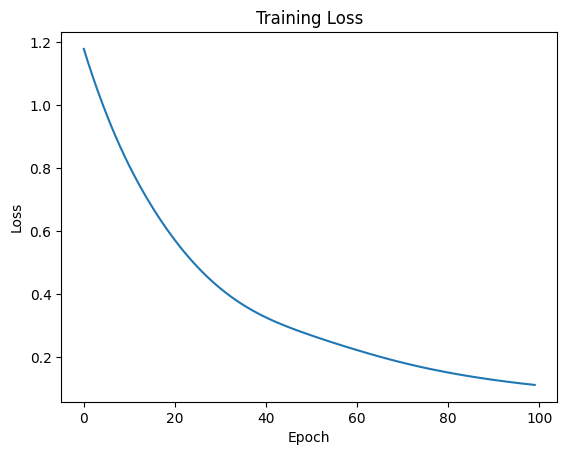

In [25]:
plt.plot(train_losses)
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

In [26]:
#Step 10 : Evaluate the model

In [27]:
model.eval()  # this eval function keeps the model in evaluation mode

with torch.no_grad():  # gradient calculation stops here
    test_outputs = model(X_test)
    predicted_classes = torch.argmax(  # from three class scores, gives the index of the highest one
        test_outputs,
        dim=1
    )  # ex. model output=[0.5, 2.8, 0.3], predicted class: 1 = Versicolor

    accuracy = (
        predicted_classes == y_test
    ).float().mean()

    print(
        f"Test Accuracy: {accuracy.item() * 100:.2f}%"
    )


Test Accuracy: 96.67%


In [28]:
import numpy as np
import torch

# Define the new flower measurements (sepal length, sepal width, petal length, petal width)
new_flower = np.array([[5.1, 3.5, 1.4, 0.2]])

# Apply the same scaler used during training
new_flower_scaled = scaler.transform(new_flower)

# Convert to PyTorch tensor
new_flower_tensor = torch.tensor(
    new_flower_scaled,
    dtype=torch.float32
)

# Make prediction
model.eval()
with torch.no_grad():
    output = model(new_flower_tensor)
    probabilities = torch.softmax(output, dim=1)
    predicted_class = torch.argmax(probabilities, dim=1).item()

print("Probabilities:", probabilities)
print("Predicted Flower:", iris.target_names[predicted_class])


Probabilities: tensor([[9.9126e-01, 8.6729e-03, 6.5111e-05]])
Predicted Flower: setosa
